# Phase 22 — Extended subgroup / fairness analysis with uncertainty (proposed RF)
**Resolves:** R2-7 (Study 2 part): CIs around subgroup recall/precision; specificity, FPR, calibration (observed - mean predicted),
predicted-risk distribution and prevalence per subgroup; separation of "intended equity rule" vs "unintended disparity";
discussion of using the stratifying variable as a predictor (ablation: refit WITHOUT that variable).

Per subgroup level: n, prevalence, predicted-positive rate, TPR (recall) + Wilson CI, FPR + Wilson CI, PPV, mean predicted risk,
observed - predicted, AUC + CI. Per variable: between-level TPR/FPR gaps with bootstrap CIs and chi-square heterogeneity p-values.
Levels with < 10 positives (TPR) or < 10 negatives (FPR) are flagged unreliable per quantity and EXCLUDED from the gap statistics.
**Outputs:** `S2_subgroup_extended.csv`, `S2_subgroup_gaps.csv`, `S2_subgroup_ablation_gaps.csv`, figure `S2_subgroup_tpr_fpr.png`

In [1]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
from revision_utils import *

ENV = get_env()          # paths + config (notebooks must be run from the notebooks/ folder)
SEED = ENV["SEED"]       # 42
B = ENV["N_BOOT"]        # 2000 bootstrap resamples (config.yaml)
print("Project root:", ENV["ROOT"], "| outputs ->", ENV["REV"])

Project root: C:\maternal-mental-health-risk | outputs -> C:\maternal-mental-health-risk\reports/tables\revision


Saved figure: C:\maternal-mental-health-risk\reports\figures\revision\S2_subgroup_tpr_fpr.png


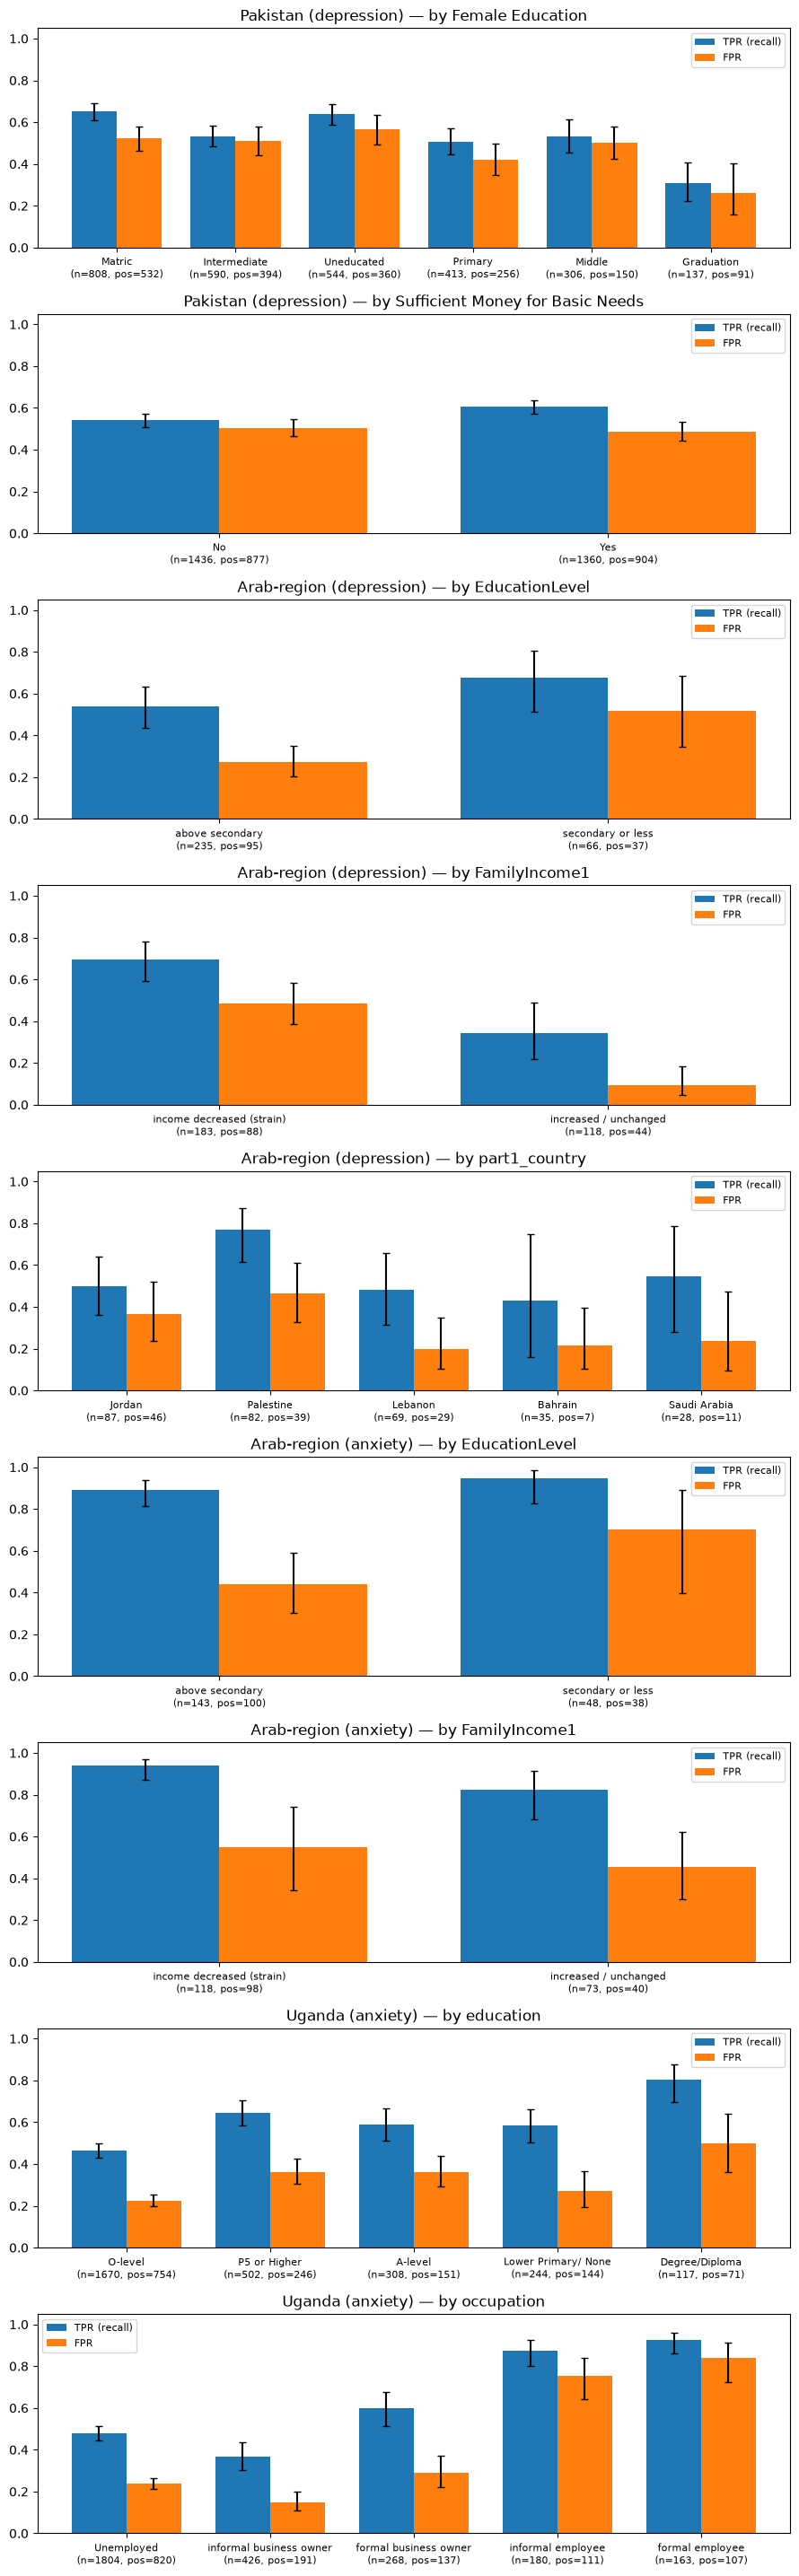

Saved: C:\maternal-mental-health-risk\reports/tables\revision\S2_subgroup_extended.csv  (31 rows)
Saved: C:\maternal-mental-health-risk\reports/tables\revision\S2_subgroup_gaps.csv  (9 rows)
Saved: C:\maternal-mental-health-risk\reports/tables\revision\S2_subgroup_ablation_gaps.csv  (9 rows)
             dataset                          variable             subgroup_level     n  n_positive  prevalence  tpr_recall    fpr  tpr_reliable  fpr_reliable
0           pakistan                  Female Education                     Matric   808         532       0.658       0.650  0.522          True          True
1           pakistan                  Female Education               Intermediate   590         394       0.668       0.533  0.510          True          True
2           pakistan                  Female Education                 Uneducated   544         360       0.662       0.639  0.565          True          True
3           pakistan                  Female Education                 

In [2]:
import matplotlib; import matplotlib.pyplot as plt
from plotting_utils import save_fig
from modeling import build_model_pipeline, tune_threshold
sub_rows, gap_rows, abl_rows = [], [], []
panels = [(t, c) for t, d in DATASETS.items() for c in d["subgroups"]]
fig, axes = plt.subplots(len(panels), 1, figsize=(9, 3.2 * len(panels)))
for ax, (tag, col) in zip(axes, panels):
    d = DATASETS[tag]; S = load_split(tag, ENV); thr = load_final_threshold(tag, ENV)
    y = S["pred_test"]["y_true"].values; p = S["pred_test"]["rf"].values
    g = pretty_levels(col, S["test"][col])
    t = subgroup_table(y, p, thr, g, B_auc=min(B, 1000), seed=SEED); t.insert(0, "variable", col); t.insert(0, "dataset", tag); sub_rows.append(t)
    gp = subgroup_gaps(y, p, thr, g, B=B, seed=SEED); gp.update(dataset=tag, variable=col, threshold=thr); gap_rows.append(gp)
    x = np.arange(len(t)); w = 0.38
    ax.bar(x - w / 2, t.tpr_recall, w, yerr=[t.tpr_recall - t.tpr_ci_lower, t.tpr_ci_upper - t.tpr_recall], capsize=3, label="TPR (recall)")
    ax.bar(x + w / 2, t.fpr, w, yerr=[t.fpr - t.fpr_ci_lower, t.fpr_ci_upper - t.fpr], capsize=3, label="FPR")
    ax.set_xticks(x); ax.set_xticklabels([f"{l}\n(n={n}, pos={q})" for l, n, q in zip(t.subgroup_level, t.n, t.n_positive)], fontsize=8)
    ax.set_title(f"{d['pretty']} — by {col}"); ax.set_ylim(0, 1.05); ax.legend(fontsize=8)
    # ablation: refit without the stratifying variable (hyperparameters fixed; threshold re-tuned on the calibration partition)
    if col in d["numeric"] + d["categorical"]:
        num = [c for c in d["numeric"] if c != col]; cat = [c for c in d["categorical"] if c != col]
        pipe = build_model_pipeline("rf", load_rf_params(tag, ENV)["rf"], num, cat, SEED)
        pipe.fit(S["train"][num + cat], S["train"][d["label"]])
        thr2, _ = tune_threshold(S["cal"][d["label"]].values, pipe.predict_proba(S["cal"][num + cat])[:, 1])
        p_abl = pipe.predict_proba(S["test"][num + cat])[:, 1]
        ga = subgroup_gaps(y, p_abl, thr2, g, B=B, seed=SEED)
        ga.update(dataset=tag, variable=col, threshold=thr2, test_auc_without_variable=safe_auc(y, p_abl), test_auc_with_variable=safe_auc(y, p)); abl_rows.append(ga)
plt.tight_layout(); save_fig(fig, "S2_subgroup_tpr_fpr.png", ENV["ROOT"], dataset="revision"); plt.show()
ext = pd.concat(sub_rows, ignore_index=True); save_table(ext, ENV, "S2_subgroup_extended.csv")
save_table(pd.DataFrame(gap_rows), ENV, "S2_subgroup_gaps.csv"); save_table(pd.DataFrame(abl_rows), ENV, "S2_subgroup_ablation_gaps.csv")
print(ext[["dataset", "variable", "subgroup_level", "n", "n_positive", "prevalence", "tpr_recall", "fpr", "tpr_reliable", "fpr_reliable"]].round(3).to_string())

**Interpretation guide:** recall differences between subgroups are partly mechanical when prevalence and predicted-positive rates differ
(a group with higher prevalence and higher mean predicted risk will show higher TPR *and* higher FPR). The manuscript must therefore
report TPR and FPR together, present the gap CIs, and describe the pattern as a *disparity in error rates* unless it was an intended
equity-oriented rule — which the threshold (single, macro-F1-tuned, not group-specific) was not. Because the stratifying variable is itself a
model input, discuss the ablation table: if gaps persist without the variable, they come from correlated predictors.